# BIO216 Coursework 2: Binary Classification for Diabetes Diagnosis
**Yuewei Xu **

## 1. Overview

This notebook implements a complete, reproducible machine-learning workflow for binary diabetes diagnosis classification using the `diabetes_data.csv` dataset. 

</br>

The study is designed on basis of the publicly available [Diabetes Health Dataset](https://www.kaggle.com/datasets/rabieelkharoua/diabetes-health-dataset-analysis) hosted on Kaggle by Rabie El kharoua.

The data set contains :
- 1,879 patients, uniquely identified with IDs ranging from 6000 to 7878.
- In total 44 columns of tabular clinical and laboratory measurements.
- A binary target variable `Diagnosis` indicating diabetes vs. non-diabetes:
    - `0` – diabetes absent.
    - `1` – diabetes present.

</br>

The workflow includes:
- Dataset analysis & preprocessing
- Model development & hyperparameter tuning:
    1. Random Forest
    2. Gradient Boosting
    3. Logistic Regression
    4. Support Vector Machine
    5. K-Nearest Neighbours
- Model evaluation
- Feature importance analysis:
    1. Coefficients
    2. Feature Importance
    3. SHAP Analysis
    4. Permutation Importance

Global Preparation

In [346]:
# Packages
import os
import shap
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.base import clone
from sklearn.decomposition import PCA

from sklearn.inspection import permutation_importance

In [67]:
# Global settings
np.random.seed(42)
sns.set_theme(style="whitegrid", font_scale=1.05)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
# os.makedirs("figures", exist_ok=True)
# os.makedirs("tables", exist_ok=True)

## 2. Data analysis and preprocessing

### 1. Load data set from CSV file

In [51]:
# 1. Data loading
file_path = "diabetes_data.csv"
try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully.")
    print(f"Dataset shape: {df.shape[0]} rows * {df.shape[1]} columns")
    display(df.head())
except FileNotFoundError:
    print(f"File not found in: {file_path}. Please check whether the file path is correct.")
    exit(1)

Dataset loaded successfully.
Dataset shape: 1879 rows * 46 columns


,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryDiabetes,GestationalDiabetes,PolycysticOvarySyndrome,PreviousPreDiabetes,Hypertension,SystolicBP,DiastolicBP,FastingBloodSugar,HbA1c,SerumCreatinine,BUNLevels,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,AntihypertensiveMedications,Statins,AntidiabeticMedications,FrequentUrination,ExcessiveThirst,UnexplainedWeightLoss,FatigueLevels,BlurredVision,SlowHealingSores,TinglingHandsFeet,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,DoctorInCharge
0,6000,44,0,1,2,1,32.985284,1,4.499365,2.443385,4.898831,4.049885,1,1,0,0,0,93,73,163.687162,9.283631,2.665607,28.190147,254.270670,86.993627,70.801469,190.335834,0,0,1,0,0,0,9.534169,0,0,1,73.765109,0,0,0,1.782724,4.486980,7.211349,1,Confidential
1,6001,51,1,0,1,2,39.916764,0,1.578919,8.301264,8.941093,7.508150,0,0,0,0,0,165,99,188.347070,7.326870,4.172177,32.149491,155.358831,110.056105,39.900112,81.172469,0,0,0,0,0,0,0.123214,0,0,0,91.445753,0,0,1,3.381070,5.961705,5.024612,1,Confidential
2,6002,89,1,0,1,3,19.782251,0,1.177301,6.103395,7.722543,7.708387,1,0,0,0,0,119,91,127.703653,4.083426,1.973168,10.018375,231.608922,62.035793,62.480666,279.809069,1,1,0,0,0,0,9.643320,0,0,0,54.485744,0,0,0,2.701019,8.950821,7.034944,0,Confidential
3,6003,21,1,1,1,2,32.376881,1,1.714621,8.645465,4.804044,6.286548,1,1,0,1,0,169,87,82.688415,6.516645,3.057797,44.123281,176.592374,68.238410,46.977819,112.751396,0,0,1,0,0,0,3.403557,0,0,0,77.866758,0,0,1,1.409056,3.124769,4.717774,0,Confidential
4,6004,27,1,0,1,3,16.808600,0,15.462549,4.629383,2.532756,9.771125,0,0,0,0,0,165,69,90.743395,5.607222,4.150353,7.757117,157.344121,66.476215,40.059755,381.528785,1,1,0,0,0,0,2.924687,0,0,0,37.731808,0,0,0,1.218452,6.977741,7.887940,0,Confidential


### 2. Preprocessing pipeline:
1. check duplicated rows/ids
2. check missing values
3. check non-numeric columns
4. specify columns used for modelling
5. one-hot expansion for multi-class categorical variables
- note that outliers are not processed here to remain clinical integrtity of the dataset

In [53]:
# 2. Data preprocessing
# Duplicated row/id check
n_duplicate_rows = df.duplicated().sum()
n_duplicate_patient_ids = df["PatientID"].duplicated().sum()
print(f"Number of duplicated rows: {n_duplicate_rows}")
print(f"Number of duplicated PatientID values: {n_duplicate_patient_ids} \n")

# Missing value check
n_missing = df.isna().sum().sum()
print(f"Number of missing values: {n_missing} \n")
if n_missing > 0:
    df = df.dropna()

# Non-numeric column check
non_numeric_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print(f"Non-numeric columns: {non_numeric_cols}, these will be dropped below.\n")

# Drop columns not used for modelling
drop_cols = ['PatientID', 'DoctorInCharge']
for col in drop_cols:
    if col in df.columns:
        df = df.drop(col, axis=1)

# One-hot expansion for multi-class categorical columns
categorical_cols = ["Ethnicity", "SocioeconomicStatus", "EducationLevel"] # recognized by manual check
df_cat = df[categorical_cols]

onehot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int
)

df_cat_encoded_array = onehot_encoder.fit_transform(df_cat)
encoded_feature_names = onehot_encoder.get_feature_names_out(categorical_cols)

df_cat_encoded = pd.DataFrame(
    df_cat_encoded_array,
    columns=encoded_feature_names,
    index=df.index
)
df_without_cat = df.drop(columns=categorical_cols)
df = pd.concat([df_without_cat, df_cat_encoded], axis=1)

# Preprocessed dataset for downstream analysis
display(df.head())
print(f"Processed dataset shape: {df.shape[0]} rows * {df.shape[1]} columns")

Number of duplicated rows: 0
Number of duplicated PatientID values: 0 

Number of missing values: 0 

Non-numeric columns: ['DoctorInCharge'], these will be dropped below.



,Age,Gender,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryDiabetes,GestationalDiabetes,PolycysticOvarySyndrome,PreviousPreDiabetes,Hypertension,SystolicBP,DiastolicBP,FastingBloodSugar,HbA1c,SerumCreatinine,BUNLevels,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,AntihypertensiveMedications,Statins,AntidiabeticMedications,FrequentUrination,ExcessiveThirst,UnexplainedWeightLoss,FatigueLevels,BlurredVision,SlowHealingSores,TinglingHandsFeet,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,Ethnicity_0,Ethnicity_1,Ethnicity_2,Ethnicity_3,SocioeconomicStatus_0,SocioeconomicStatus_1,SocioeconomicStatus_2,EducationLevel_0,EducationLevel_1,EducationLevel_2,EducationLevel_3
0,44,0,32.985284,1,4.499365,2.443385,4.898831,4.049885,1,1,0,0,0,93,73,163.687162,9.283631,2.665607,28.190147,254.270670,86.993627,70.801469,190.335834,0,0,1,0,0,0,9.534169,0,0,1,73.765109,0,0,0,1.782724,4.486980,7.211349,1,0,1,0,0,0,0,1,0,1,0,0
1,51,1,39.916764,0,1.578919,8.301264,8.941093,7.508150,0,0,0,0,0,165,99,188.347070,7.326870,4.172177,32.149491,155.358831,110.056105,39.900112,81.172469,0,0,0,0,0,0,0.123214,0,0,0,91.445753,0,0,1,3.381070,5.961705,5.024612,1,1,0,0,0,0,1,0,0,0,1,0
2,89,1,19.782251,0,1.177301,6.103395,7.722543,7.708387,1,0,0,0,0,119,91,127.703653,4.083426,1.973168,10.018375,231.608922,62.035793,62.480666,279.809069,1,1,0,0,0,0,9.643320,0,0,0,54.485744,0,0,0,2.701019,8.950821,7.034944,0,1,0,0,0,0,1,0,0,0,0,1
3,21,1,32.376881,1,1.714621,8.645465,4.804044,6.286548,1,1,0,1,0,169,87,82.688415,6.516645,3.057797,44.123281,176.592374,68.238410,46.977819,112.751396,0,0,1,0,0,0,3.403557,0,0,0,77.866758,0,0,1,1.409056,3.124769,4.717774,0,0,1,0,0,0,1,0,0,0,1,0
4,27,1,16.808600,0,15.462549,4.629383,2.532756,9.771125,0,0,0,0,0,165,69,90.743395,5.607222,4.150353,7.757117,157.344121,66.476215,40.059755,381.528785,1,1,0,0,0,0,2.924687,0,0,0,37.731808,0,0,0,1.218452,6.977741,7.887940,0,1,0,0,0,0,1,0,0,0,0,1


### 3. Exploratory data analysis (EDA)
- For all columns: analysis their correlation
- For diagnosis label: detect class distribution and balance 

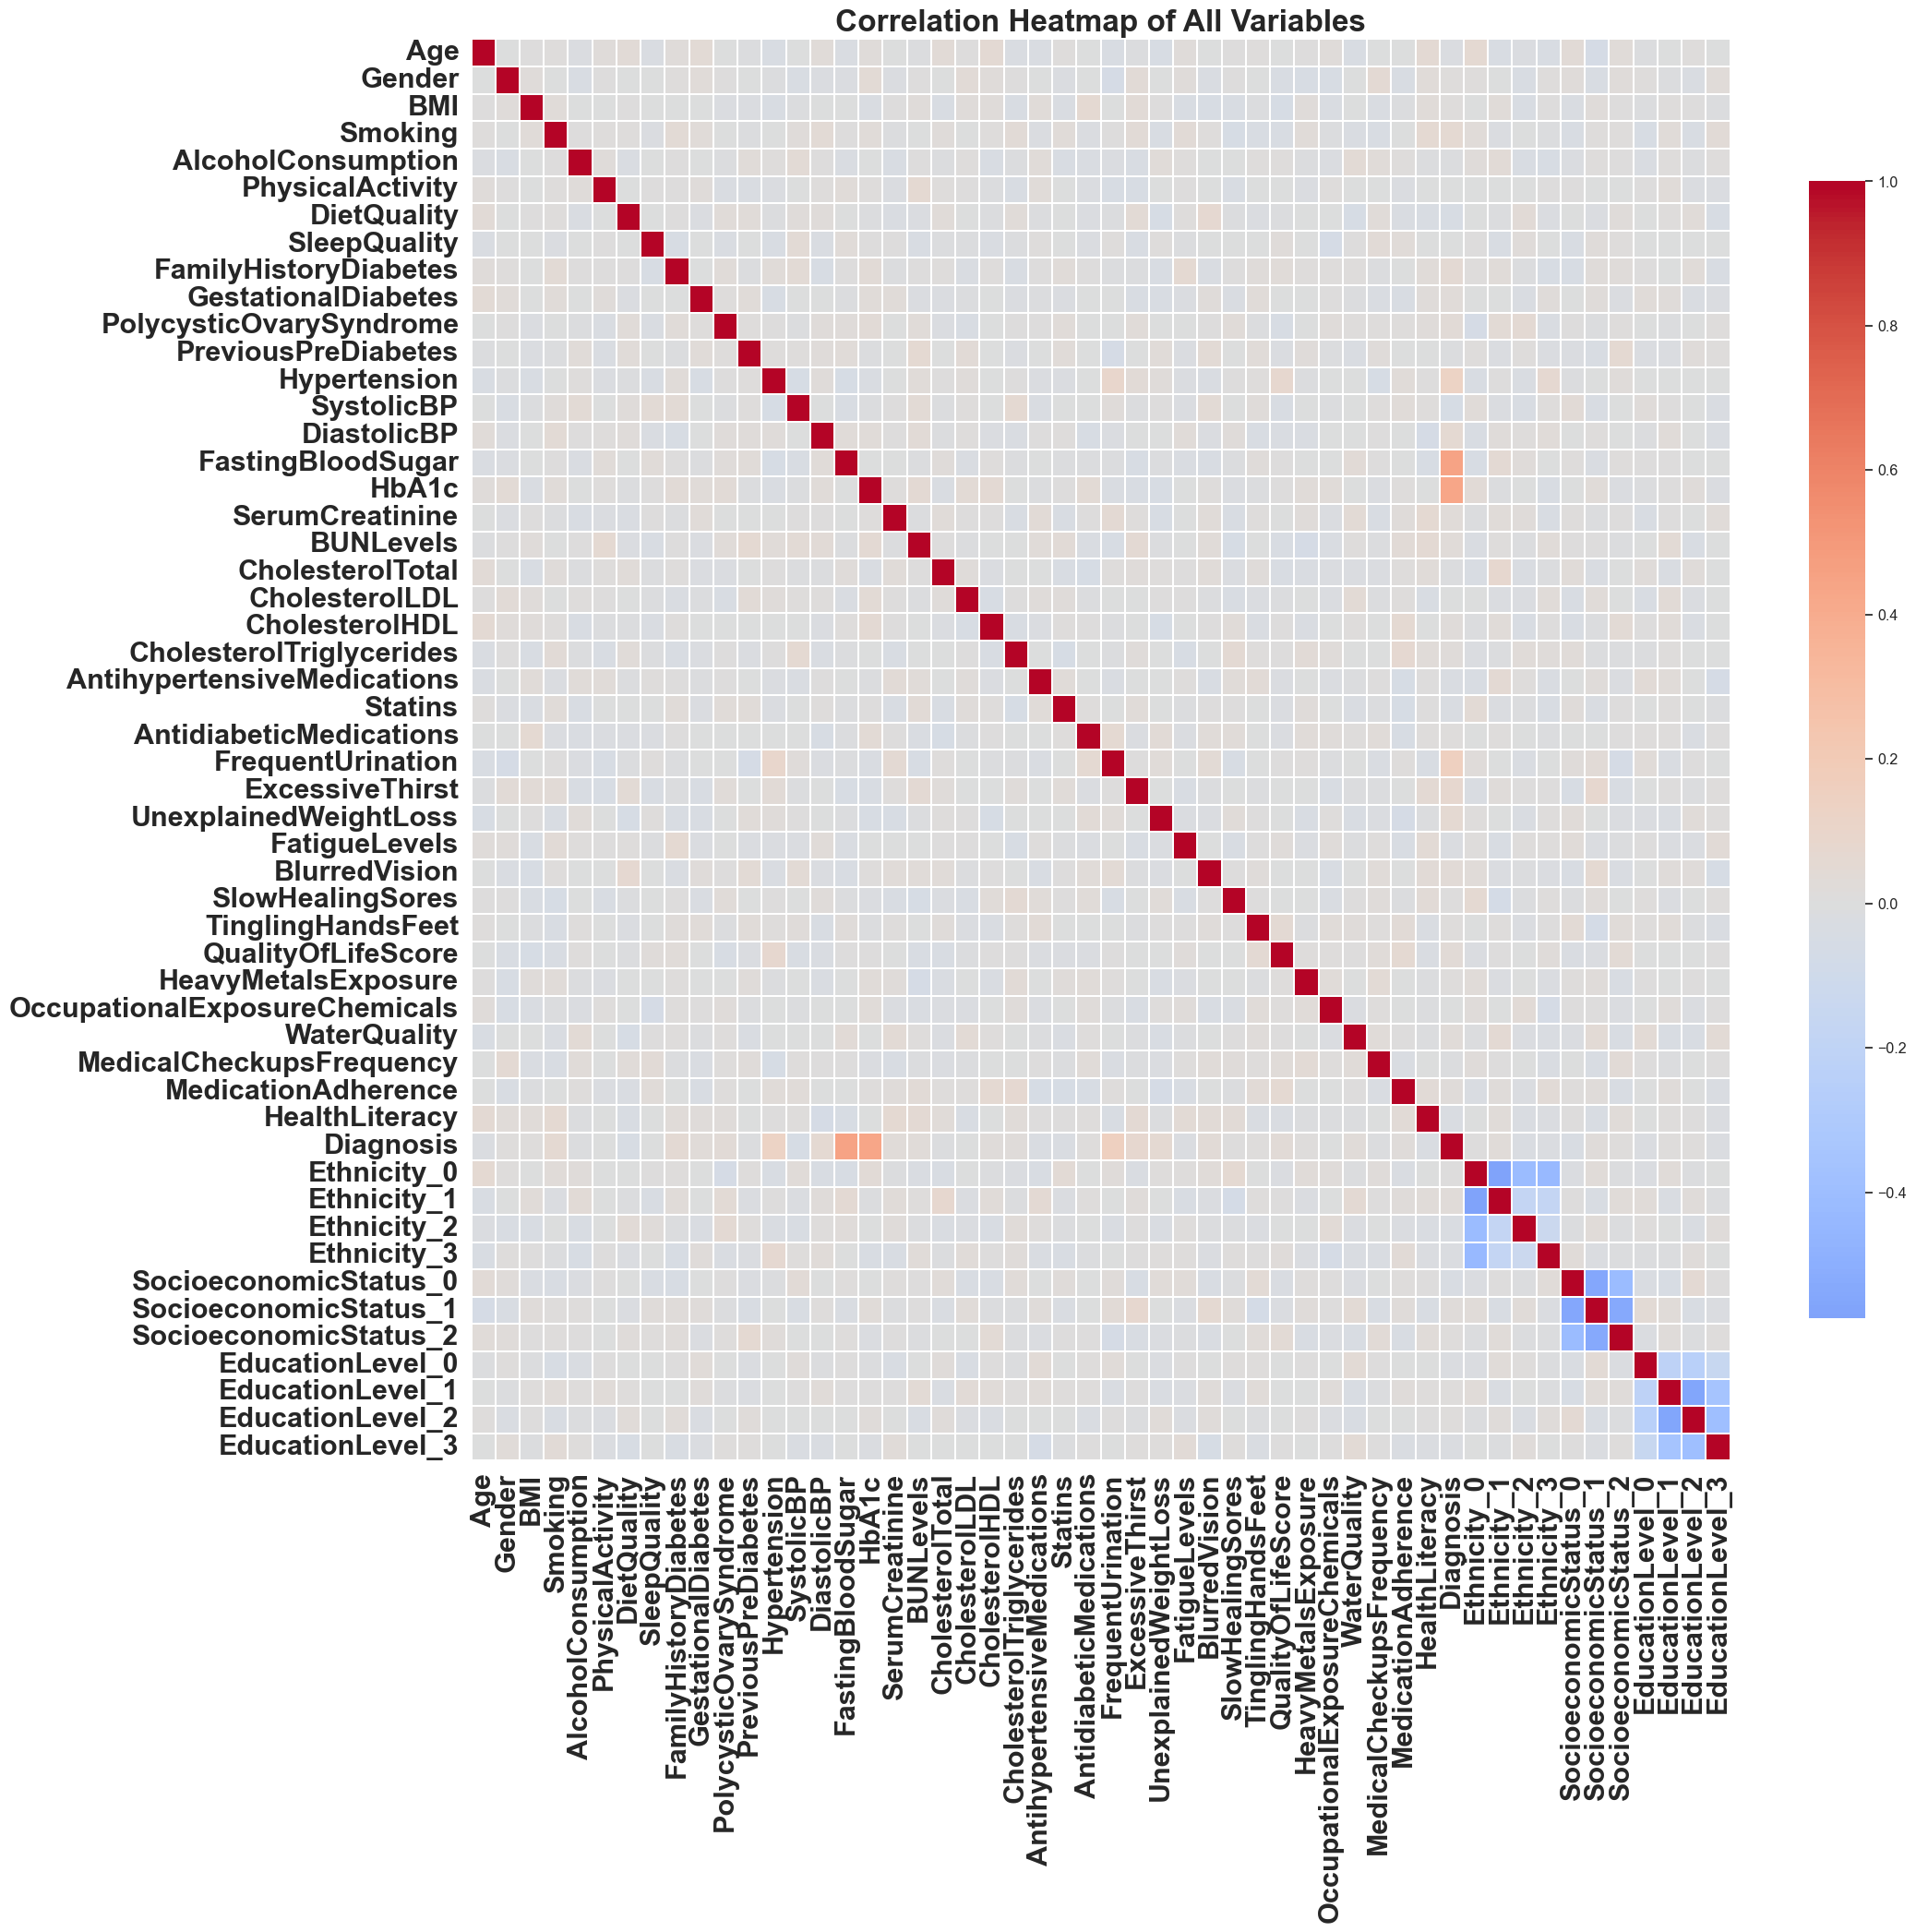

,Correlation_with_Diagnosis
FastingBloodSugar,0.4520
HbA1c,0.4311
FrequentUrination,0.1515
Hypertension,0.1319
ExcessiveThirst,0.0735


In [264]:
# Correlation matrix
corr_matrix = df.corr()

# Correlation heatmap
plt.figure(figsize=(22, 20))
ax = sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2,
    cbar_kws={"shrink": 0.8},
    xticklabels=True,
    yticklabels=True
)
plt.title("Correlation Heatmap of All Variables", fontsize=24, weight="bold")
plt.xticks(rotation=90, fontsize=22, weight="bold")
plt.yticks(rotation=0, fontsize=22, weight="bold")
# plt.savefig("../Data/figures/1_correlation_heatmap.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

# Features most correlated with Diagnosis (top 5)
diagnosis_corr = (
    corr_matrix["Diagnosis"]
    .drop("Diagnosis")
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .to_frame(name="Correlation_with_Diagnosis")
)
# diagnosis_corr.head(5).round(4).to_csv("../Data/tables/1_diagnosis_correlation_top5.csv")
display(diagnosis_corr.head(5).round(4))

,Count,Percentage(%)
Diagnosis,,
No Diabetes (0),1127,59.98
Diabetes (1),752,40.02


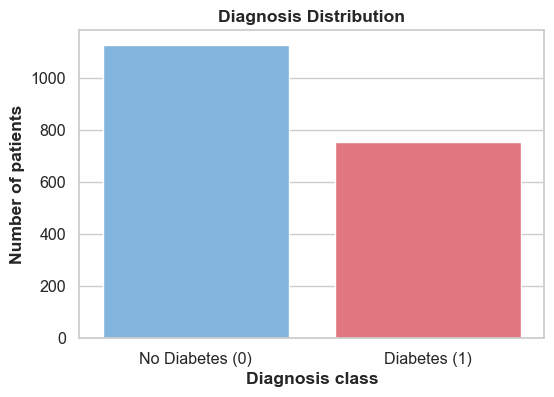

In [176]:
# Distribution of diagnosis labels
diagnosis_counts = df["Diagnosis"].value_counts().sort_index()
diagnosis_percentages = df["Diagnosis"].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({
    "Count": diagnosis_counts,
    "Percentage(%)": diagnosis_percentages.round(2)
})
target_summary.index = target_summary.index.map({
    0: "No Diabetes (0)",
    1: "Diabetes (1)"
})
# target_summary.to_csv("../Data/tables/2_diagnosis_distribution.csv")
display(target_summary)

plt.figure(figsize=(6, 4))
sns.barplot(
    x=target_summary.index,
    y=target_summary["Count"],
    hue=target_summary.index,
    palette=["#71b7ed", "#f2656f"],
    legend=False
)
plt.ylabel("Number of patients", weight="bold")
plt.xlabel("Diagnosis class", weight="bold")
plt.title("Diagnosis Distribution", weight="bold")
# plt.savefig("../Data/figures/2_diagnosis_distribution.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

> The dataset shows a mild class imbalance, with non-diabetic patients forming the majority class. Therefore, stratified sampling was used during train-test splitting, and model performance was evaluated using precision, recall/sensitivity, specificity, F1-score, ROC-AUC and PR-AUC in addition to accuracy.

### 4. Feature selection and data splitting
1. Divide columns into predictors `X`, and classification label `y`
2. Split dataset into training set and testing set (80:20)
3. Define 5-fold cross-validation (CV)

In [106]:
# Columns divide
X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # Keep the class ratio of diagnosis label similar in train and test sets, due to mile imbalance class distribution
)

# 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

### 5. Feature scaling for scale-sensitive models
- Using eqation: $z = \frac{x - \mu}{\sigma}$

In [109]:
# Scale continuous variables (recognized by manual check)
scale_cols = df.select_dtypes(include=["float64"]).columns.tolist()
scale_cols += ["Age", "SystolicBP", "DiastolicBP"]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit scaler on training set only and apply to testing set to avoid data leakage
scaler = StandardScaler()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

display(X_train_scaled.head())

,Age,Gender,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryDiabetes,GestationalDiabetes,PolycysticOvarySyndrome,PreviousPreDiabetes,Hypertension,SystolicBP,DiastolicBP,FastingBloodSugar,HbA1c,SerumCreatinine,BUNLevels,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,AntihypertensiveMedications,Statins,AntidiabeticMedications,FrequentUrination,ExcessiveThirst,UnexplainedWeightLoss,FatigueLevels,BlurredVision,SlowHealingSores,TinglingHandsFeet,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Ethnicity_0,Ethnicity_1,Ethnicity_2,Ethnicity_3,SocioeconomicStatus_0,SocioeconomicStatus_1,SocioeconomicStatus_2,EducationLevel_0,EducationLevel_1,EducationLevel_2,EducationLevel_3
183,0.641089,1,0.153909,1,0.963418,1.276996,-0.402913,1.456607,0,0,0,0,0,0.709226,-0.217505,-1.712251,0.176823,1.062245,-1.547560,1.020257,1.258124,1.000339,-0.529166,0,1,0,1,0,0,-0.657320,0,0,0,-1.017275,0,0,1,0.516093,0.209185,-1.423548,1,0,0,0,0,0,1,0,0,1,0
978,-0.193117,0,-1.115692,0,-1.615760,1.008037,1.675041,-1.531391,0,0,0,0,0,-0.151213,-0.333513,-0.168826,1.278951,-0.250876,-0.833460,1.362923,1.430778,-0.526549,0.660457,0,0,1,0,0,0,1.262553,0,0,0,0.408046,0,1,0,1.672541,-1.096473,-0.735534,1,0,0,0,0,0,1,0,0,0,1
1804,1.720650,1,-0.915273,0,-0.800978,-0.249384,0.202383,-0.936336,0,1,0,0,0,-1.598315,-1.087565,1.132224,-1.694527,-1.073871,0.903521,-1.434615,0.599302,1.419715,0.508737,0,1,1,1,0,0,-0.174287,0,0,0,-0.815493,0,0,0,-0.672086,0.331610,-1.324112,1,0,0,0,0,1,0,0,0,0,1
501,0.297593,0,0.462178,1,1.452897,-1.087530,-0.586080,1.094565,0,1,0,0,1,-1.207206,-1.609601,1.653167,-0.965700,1.150843,-1.753691,1.567975,-1.722521,-1.400098,-0.906417,1,0,1,0,0,0,0.577111,0,0,0,0.429007,0,1,0,-1.000970,-0.936022,0.889354,1,0,0,0,0,1,0,0,0,0,1
449,-0.831039,1,0.278445,1,1.292824,0.558478,0.421227,-0.296104,0,0,0,1,0,-0.972541,-0.449521,1.045257,0.435397,-1.493242,0.319139,0.269428,1.229999,1.613591,-0.557095,0,0,0,1,0,1,-1.513373,1,0,0,0.355576,0,0,1,1.611956,0.548819,-1.078496,1,0,0,0,0,1,0,0,1,0,0


## 3. Model development & hyperparameter tuning
**Each chunk takes a while, please decrease value for parameter `niter=50` to speed up calculations.**

### 1. Random Forest
Random Forest is flexible because it combines many decision trees and can model non-linear effects while being relatively robust to outliers. However, its predictions are less transparent and impurity-based feature importance can be biased toward continuous variables.

In [122]:
# 1. Random Forest

# Base model
rf_base = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",     # prevent from biased towards non-diabetes cases due to mildly imbalanced dataset
    n_jobs=-1
)

# Hyperparameter search space
rf_param_dist = {
    "n_estimators": [300, 500, 800, 1000],      # Number of trees in the forest
    "max_depth": [None, 5, 10, 15, 20, 30],     # Maximum depth of each tree; None allows full expansion
    "min_samples_split": [2, 5, 10, 20],        # Minimum samples required to split an internal node
    "min_samples_leaf": [1, 2, 4, 8],           # Minimum samples required in a leaf node
    "max_features": ["sqrt", "log2", 0.5],      # Number/proportion of features considered at each split
    "bootstrap": [True]                         # Train each tree on a bootstrap sample of the training data
}

# Hyperparameter tuning using multiple hyperparameter combinations
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=rf_param_dist,
    n_iter=50,             # Try 50 iterations
    scoring="roc_auc",     # Use ROC-AUC to evaluate performance
    cv=cv,                 # Stratified 5-fold cross-validation
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
rf_search.fit(X_train, y_train)

# Extract the best model
best_rf = rf_search.best_estimator_

# Results
print("Best Random Forest CV ROC-AUC:", round(rf_search.best_score_, 4))
print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best Random Forest model:")
display(best_rf)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Random Forest CV ROC-AUC: 0.9549
Best Random Forest parameters:
{'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10, 'bootstrap': True}
Best Random Forest model:


RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=4, min_samples_split=10,
                       n_estimators=500, n_jobs=-1, random_state=42)

### 2. Gradient Boosting
Gradient Boosting usually achieves strong predictive performance by sequentially correcting previous errors, which makes it effective for complex tabular data, but it is more sensitive to hyperparameter choices and may overfit if model complexity is not controlled. 

In [136]:
# 2. Gradient Boosting

# Base model
gb_base = GradientBoostingClassifier(
    random_state=42
)

# Hyperparameter search space
gb_param_dist = {
    "n_estimators": [100, 200, 300],              # Number of boosting stages
    "learning_rate": [0.01, 0.03, 0.05, 0.1],     # Contribution of each tree to the final model
    "max_depth": [2, 3, 4, 5],                    # Maximum depth of each individual tree
    "min_samples_split": [2, 5, 10],              # Minimum samples required to split an internal node
    "min_samples_leaf": [1, 2, 4],                # Minimum samples required in a leaf node
    "subsample": [0.8, 1.0],                      # Fraction of samples used to fit each tree
    "max_features": ["sqrt", "log2", None]        # Number of features considered at each split
}

# Hyperparameter tuning using multiple hyperparameter combinations
gb_search = RandomizedSearchCV(
    estimator=gb_base,
    param_distributions=gb_param_dist,
    n_iter=50,             # Try 50 iterations
    scoring="roc_auc",     # Use ROC-AUC to evaluate performance
    cv=cv,                 # Stratified 5-fold cross-validation
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
gb_search.fit(X_train, y_train)

# Extract the best model
best_gb = gb_search.best_estimator_

# Results
print("Best Gradient Boosting CV ROC-AUC:", round(gb_search.best_score_, 4))
print("Best Gradient Boosting parameters:")
print(gb_search.best_params_)
print("Best Gradient Boosting model:")
display(best_gb)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Gradient Boosting CV ROC-AUC: 0.9601
Best Gradient Boosting parameters:
{'subsample': 1.0, 'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 2, 'learning_rate': 0.1}
Best Gradient Boosting model:


GradientBoostingClassifier(max_depth=2, max_features='sqrt', min_samples_leaf=2,
                           n_estimators=200, random_state=42)

### 3. Logistic Regression 
Logistic Regression provides a transparent linear baseline and allows coefficient-based interpretation, but it may fail to capture non-linear relationships and feature interactions. 

In [150]:
# 3. Logistic Regression

# Base model
lr_base = LogisticRegression(
    max_iter=5000,     # Allow sufficient iterations for convergence
    random_state=42
)

# Hyperparameter search space
lr_param_dist = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],     # Inverse regularization strength; smaller C means stronger regularization
    "penalty": ["l1", "l2"],                 # L1 can perform feature selection; L2 shrinks coefficients smoothly
    "solver": ["liblinear"],                 # Supports both L1 and L2 penalties for binary classification
    "class_weight": [None, "balanced"],      # Optional correction for mild class imbalance
    "fit_intercept": [True, False],          # Whether to include an intercept term
}

# Hyperparameter tuning using multiple hyperparameter combinations
lr_search = RandomizedSearchCV(
    estimator=lr_base,
    param_distributions=lr_param_dist,
    n_iter=50,             # Try 50 iterations
    scoring="roc_auc",     # Use ROC-AUC to evaluate performance
    cv=cv,                 # Stratified 5-fold cross-validation
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
lr_search.fit(X_train_scaled, y_train)

# Extract the best model
best_lr = lr_search.best_estimator_

# Results
print("Best Logistic Regression CV ROC-AUC:", round(lr_search.best_score_, 4))
print("Best Logistic Regression parameters:")
print(lr_search.best_params_)
print("Best Logistic Regression model:")
display(best_lr)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Logistic Regression CV ROC-AUC: 0.9029
Best Logistic Regression parameters:
{'solver': 'liblinear', 'penalty': 'l1', 'fit_intercept': True, 'class_weight': 'balanced', 'C': 0.1}
Best Logistic Regression model:


LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000, penalty='l1',
                   random_state=42, solver='liblinear')

### 4. Support Vector Machine (SVM)
SVM can learn non-linear decision boundaries through kernel functions and is effective in high-dimensional settings, but it requires feature scaling and is less interpretable for clinical use. 

In [142]:
# 4. Support Vector Machine

# Base model
svm_base = SVC(
    probability=True,     # Enable probability estimates for ROC-AUC, PR-AUC and threshold-based evaluation
    random_state=42
)

# Hyperparameter search space
svm_param_dist = {
    "C": [0.1, 1, 10, 100],                    # Regularization strength; larger C allows less regularization
    "kernel": ["linear", "rbf"],               # Linear or non-linear decision boundary
    "gamma": ["scale", "auto", 0.01, 0.1],     # Influence range of each sample for the RBF kernel
    "class_weight": [None, "balanced"]         # Optional correction for mild class imbalance
}

# Hyperparameter tuning using multiple hyperparameter combinations
svm_search = RandomizedSearchCV(
    estimator=svm_base,
    param_distributions=svm_param_dist,
    n_iter=50,             # Try 50 iterations
    scoring="roc_auc",     # Use ROC-AUC to evaluate performance
    cv=cv,                 # Stratified 5-fold cross-validation
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
svm_search.fit(X_train_scaled, y_train)

# Extract the best model
best_svm = svm_search.best_estimator_

# Results
print("Best SVM CV ROC-AUC:", round(svm_search.best_score_, 4))
print("Best SVM parameters:")
print(svm_search.best_params_)
print("Best SVM model:")
display(best_svm)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best SVM CV ROC-AUC: 0.8978
Best SVM parameters:
{'kernel': 'rbf', 'gamma': 0.01, 'class_weight': 'balanced', 'C': 10}
Best SVM model:


SVC(C=10, class_weight='balanced', gamma=0.01, probability=True,
    random_state=42)

### 5. K-Nearest Neighbours (KNN)
KNN is simple and non-parametric, but it is strongly affected by feature scaling, distance metric and the choice of neighbour number.

In [154]:
# 5. K-Nearest Neighbours

# Base model
knn_base = KNeighborsClassifier()

# Hyperparameter search space
knn_param_dist = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],                # Number of neighbours used for voting
    "weights": ["uniform", "distance"],                         # Equal voting or closer-neighbour weighted voting
    "metric": ["minkowski"],                                    # General distance metric
    "algorithm": ["auto", "ball_tree", "kd_tree", "brute"],     # Nearest-neighbour search algorithm
    "p": [1, 2, 3]                                              # p=1: Manhattan distance; p=2: Euclidean distance, p=3: higher-order Minkowski distance
}

# Hyperparameter tuning using multiple hyperparameter combinations
knn_search = RandomizedSearchCV(
    estimator=knn_base,
    param_distributions=knn_param_dist,
    n_iter=50,             # Try 50 iterations
    scoring="roc_auc",     # Use ROC-AUC to evaluate performance
    cv=cv,                 # Stratified 5-fold cross-validation
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
knn_search.fit(X_train_scaled, y_train)

# Extract the best model
best_knn = knn_search.best_estimator_

# Results
print("Best KNN CV ROC-AUC:", round(knn_search.best_score_, 4))
print("Best KNN parameters:")
print(knn_search.best_params_)
print("Best KNN model:")
display(best_knn)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best KNN CV ROC-AUC: 0.8615
Best KNN parameters:
{'weights': 'uniform', 'p': 1, 'n_neighbors': 31, 'metric': 'minkowski', 'algorithm': 'ball_tree'}
Best KNN model:


KNeighborsClassifier(algorithm='ball_tree', n_neighbors=31, p=1)

### 6. Models summary dictionary

In [267]:
# M odels summary dictionary
models = {
    "Random Forest": {
        "model": best_rf,
        "X_test": X_test,
        "X_train": X_train,
        "search": rf_search
    },
    "SVM": {
        "model": best_svm,
        "X_test": X_test_scaled,
        "X_train": X_train_scaled,
        "search": svm_search
    },
    "Logistic Regression": {
        "model": best_lr,
        "X_test": X_test_scaled,
        "X_train": X_train_scaled,
        "search": lr_search
    },
    "Gradient Boosting": {
        "model": best_gb,
        "X_test": X_test,
        "X_train": X_train,
        "search": gb_search
    },
    "KNN": {
        "model": best_knn,
        "X_test": X_test_scaled,
        "X_train": X_train_scaled,
        "search": knn_search
    }
}

## 4. Model evaluation

### 1. Algorithm & function preparation
**Note that all threshold-dependent metrics are calculated using a pre-searched best threshold with highest F1-score.**

In [412]:
def get_positive_probability(model, X_te):
    '''
    Get predicted probability for positive class.
    If probability is not available, using normalized decision score instead.
    '''
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_te)[:, 1]
    else:
        scores = model.decision_function(X_te)
        return (scores - scores.min()) / (scores.max() - scores.min())

def find_best_f1_threshold(y_true, y_prob):
    '''
    Find threshold that maximises F1-score for Diabetes class.
    '''
    precision_arr, recall_arr, thresholds_arr = precision_recall_curve(y_true, y_prob)
    
    precision_valid = precision_arr[:-1]
    recall_valid = recall_arr[:-1]
    
    f1_arr = 2 * precision_valid * recall_valid / (
        precision_valid + recall_valid + 1e-12
    )
    
    best_idx = np.argmax(f1_arr)
    best_threshold = thresholds_arr[best_idx]
    
    return best_threshold, precision_arr, recall_arr, thresholds_arr, f1_arr

### 2. Individual model evaluation
For each model, show:
- Metrics table
- Classification report
- Confusion matrix
- PCA 2D projection for decision-boundary **(this method compresses information a lot, hence is not included in report for further analysis)**

In [459]:
def evaluate_one_model(model_name, model, X_te, y_true):
    '''
    Individual model evaluation.
    '''
    # Predicted probability
    y_prob = get_positive_probability(model, X_te)
    
    # Best-F1 threshold
    best_threshold, precision_curve, recall_curve, thresholds_curve, f1_curve = find_best_f1_threshold(
        y_true, y_prob
    )
    
    # Predicted labels using best-F1 threshold
    y_pred = (y_prob >= best_threshold).astype(int)
    
    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    # Metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)
    
    # Store metrics as one-row dataframe
    metrics_row = {
        "Model": model_name,
        "Best_F1_Threshold": best_threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall/Sensitivity": recall,
        "Specificity": specificity,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }
    metrics_single_df = pd.DataFrame([metrics_row])

    # Store prediction details for later ROC/PR plots
    prediction_info = {
        "y_prob": y_prob,
        "y_pred": y_pred,
        "best_threshold": best_threshold,
        "precision_curve": precision_curve,
        "recall_curve": recall_curve,
        "thresholds_curve": thresholds_curve,
        "f1_curve": f1_curve,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }
    
    # Print results
    # 1. Model name
    print(model_name)

    # 2. Metrics table
    print("\nCalculated metrics:")
    display(metrics_single_df.round(4))
    
    # 3. Classification report
    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["No Diabetes (0)", "Diabetes (1)"],
        digits=4
    ))
    
    # 4. Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)"
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Blues",
        cbar=False,
        linewidths=0.8,
        linecolor="white",
        square=True,
        xticklabels=["Predicted No Diabetes", "Predicted Diabetes"],
        yticklabels=["Actual No Diabetes", "Actual Diabetes"]
    )
    
    plt.title(f"Confusion Matrix - {model_name}", fontsize=14, weight="bold")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

    # 5. PCA projection plot
    pca = PCA(n_components=2, random_state=42)

    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    model_2d = clone(model)
    model_2d.fit(X_train_pca, y_train)

    x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
    y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    y_pred_2d = model_2d.predict(X_test_pca)
    y_true_arr = np.array(y_true)

    correct = y_pred_2d == y_true_arr
    incorrect = ~correct

    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    plt.scatter(
        X_test_pca[correct, 0],
        X_test_pca[correct, 1],
        c=y_true_arr[correct],
        cmap="viridis",
        edgecolor="k",
        s=40,
        label="Correct"
    )
    plt.scatter(
        X_test_pca[incorrect, 0],
        X_test_pca[incorrect, 1],
        c="red",
        marker="x",
        s=70,
        label="Wrong"
    )
    plt.title(f"PCA Decision Boundary - {model_name}", fontsize=14, weight="bold")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("=" * 100)
    print("=" * 100)
    print("=" * 100)

    return metrics_row, prediction_info

Random Forest

Calculated metrics:


,Model,Best_F1_Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,Random Forest,0.4169,217,9,13,137,0.9415,0.9384,0.9133,0.9602,0.9257,0.9589,0.9361



Classification report:
                 precision    recall  f1-score   support

No Diabetes (0)     0.9435    0.9602    0.9518       226
   Diabetes (1)     0.9384    0.9133    0.9257       150

       accuracy                         0.9415       376
      macro avg     0.9409    0.9368    0.9387       376
   weighted avg     0.9414    0.9415    0.9414       376



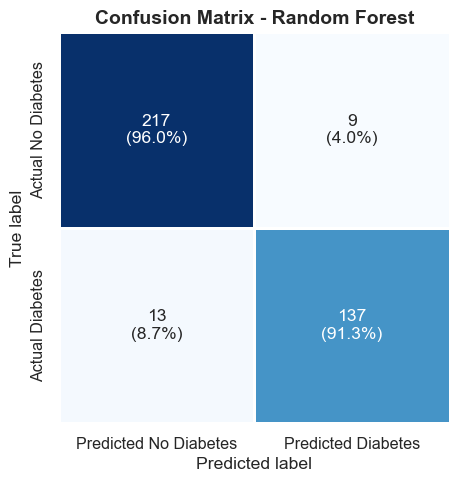

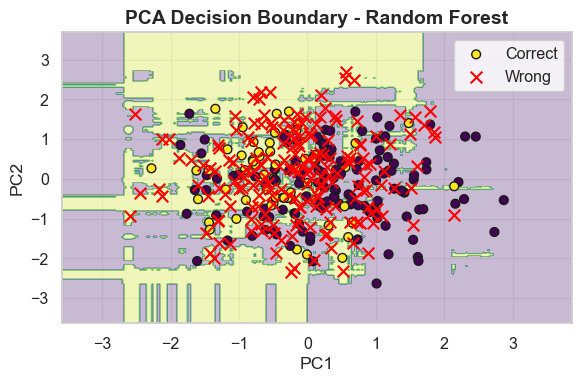

SVM

Calculated metrics:


,Model,Best_F1_Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,SVM,0.5216,207,19,28,122,0.875,0.8652,0.8133,0.9159,0.8385,0.9245,0.8968



Classification report:
                 precision    recall  f1-score   support

No Diabetes (0)     0.8809    0.9159    0.8980       226
   Diabetes (1)     0.8652    0.8133    0.8385       150

       accuracy                         0.8750       376
      macro avg     0.8730    0.8646    0.8683       376
   weighted avg     0.8746    0.8750    0.8743       376



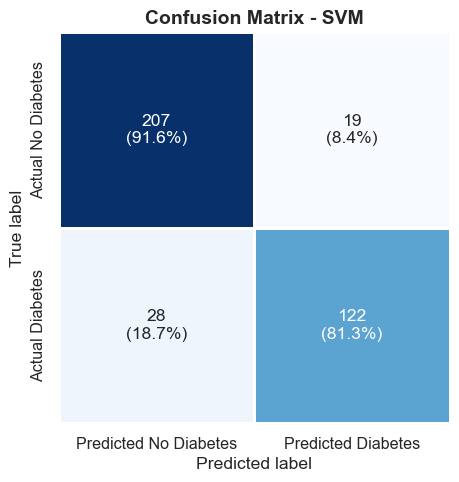

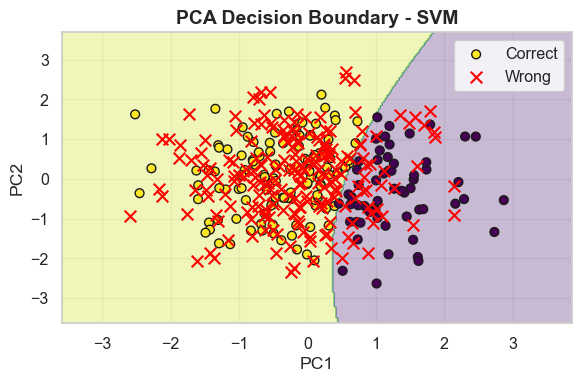

Logistic Regression

Calculated metrics:


,Model,Best_F1_Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6167,209,17,33,117,0.867,0.8731,0.78,0.9248,0.8239,0.9116,0.8776



Classification report:
                 precision    recall  f1-score   support

No Diabetes (0)     0.8636    0.9248    0.8932       226
   Diabetes (1)     0.8731    0.7800    0.8239       150

       accuracy                         0.8670       376
      macro avg     0.8684    0.8524    0.8586       376
   weighted avg     0.8674    0.8670    0.8655       376



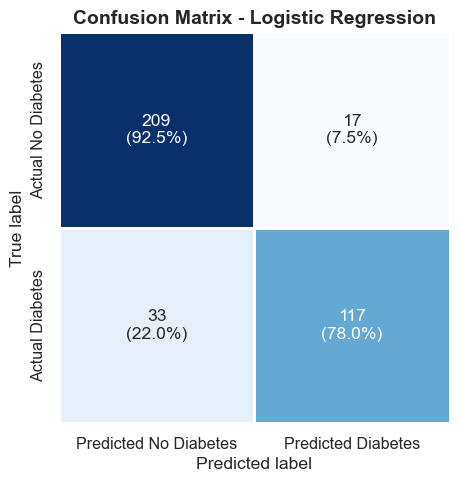

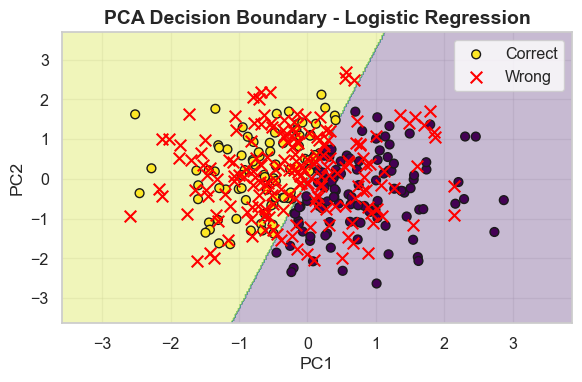

Gradient Boosting

Calculated metrics:


,Model,Best_F1_Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,Gradient Boosting,0.3749,218,8,12,138,0.9468,0.9452,0.92,0.9646,0.9324,0.9636,0.9611



Classification report:
                 precision    recall  f1-score   support

No Diabetes (0)     0.9478    0.9646    0.9561       226
   Diabetes (1)     0.9452    0.9200    0.9324       150

       accuracy                         0.9468       376
      macro avg     0.9465    0.9423    0.9443       376
   weighted avg     0.9468    0.9468    0.9467       376



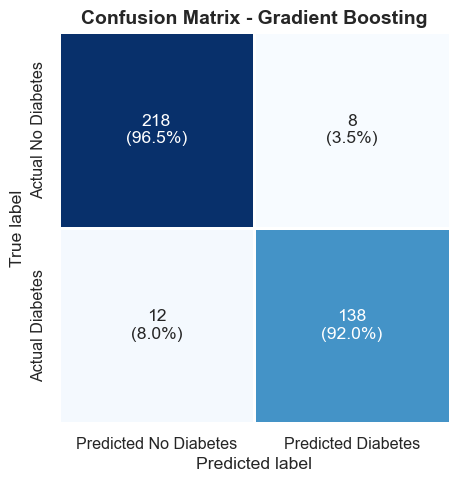

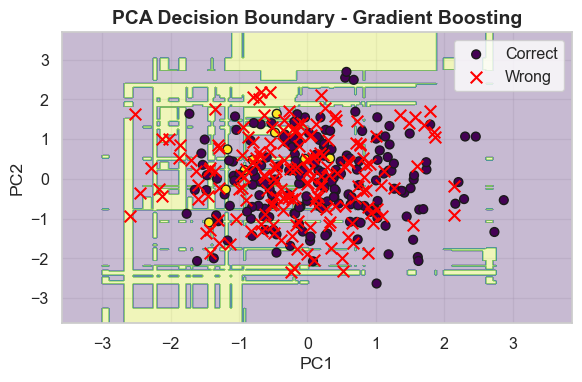

KNN

Calculated metrics:


,Model,Best_F1_Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,KNN,0.4194,186,40,25,125,0.8271,0.7576,0.8333,0.823,0.7937,0.8988,0.8457



Classification report:
                 precision    recall  f1-score   support

No Diabetes (0)     0.8815    0.8230    0.8513       226
   Diabetes (1)     0.7576    0.8333    0.7937       150

       accuracy                         0.8271       376
      macro avg     0.8195    0.8282    0.8225       376
   weighted avg     0.8321    0.8271    0.8283       376



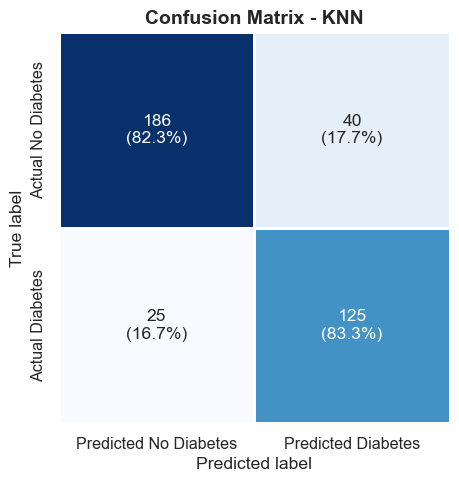

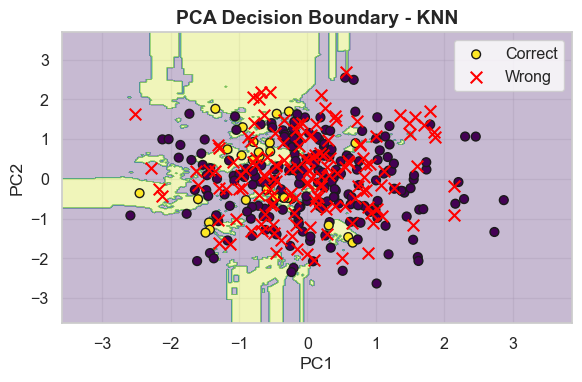

In [461]:
# Store results
evaluation_records = []
prediction_store = {}

# Individual model evaluation
for model_name, item in models.items():
    metrics_row, prediction_info = evaluate_one_model(
        model_name=model_name,
        model=item["model"],
        X_te=item["X_test"],
        y_true=y_test
    )
    
    evaluation_records.append(metrics_row)
    prediction_store[model_name] = prediction_info

### 3. Multiple model comparison
Show:
- Summary metrics table
- Combined Receiver Operating Characteristic (ROC) curves & Precision-Recall (PR) curves 
- Multi-metric comparison bar plot & radar chart
- CV ROC-AUC vs Best ROC-AUC

In [434]:
# Summary metrics table
metrics_df = pd.DataFrame(evaluation_records).round(4)
display(metrics_df)
metrics_df.to_csv("../Data/tables/3_model_evaluation_metrics.csv", index=False)

,Model,Best_F1_Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC,PR-AUC
0,Random Forest,0.4169,217,9,13,137,0.9415,0.9384,0.9133,0.9602,0.9257,0.9589,0.9361
1,SVM,0.5216,207,19,28,122,0.8750,0.8652,0.8133,0.9159,0.8385,0.9245,0.8968
2,Logistic Regression,0.6167,209,17,33,117,0.8670,0.8731,0.7800,0.9248,0.8239,0.9116,0.8776
3,Gradient Boosting,0.3749,218,8,12,138,0.9468,0.9452,0.9200,0.9646,0.9324,0.9636,0.9611
4,KNN,0.4194,186,40,25,125,0.8271,0.7576,0.8333,0.8230,0.7937,0.8988,0.8457


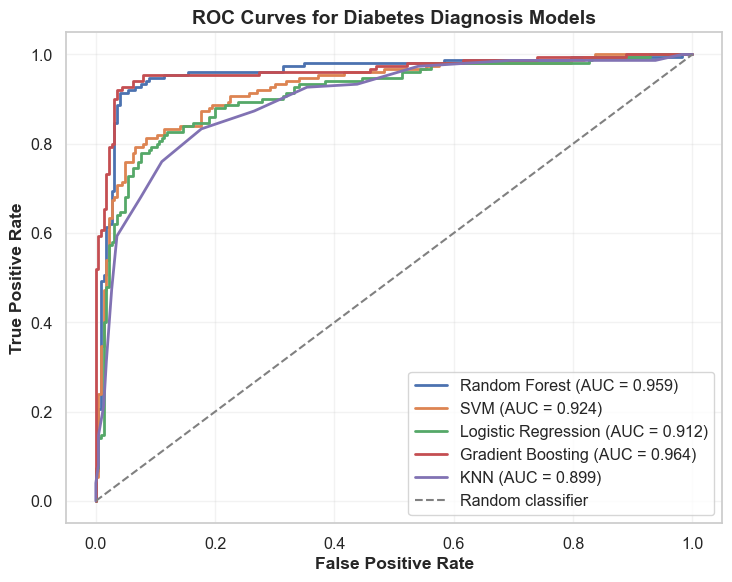

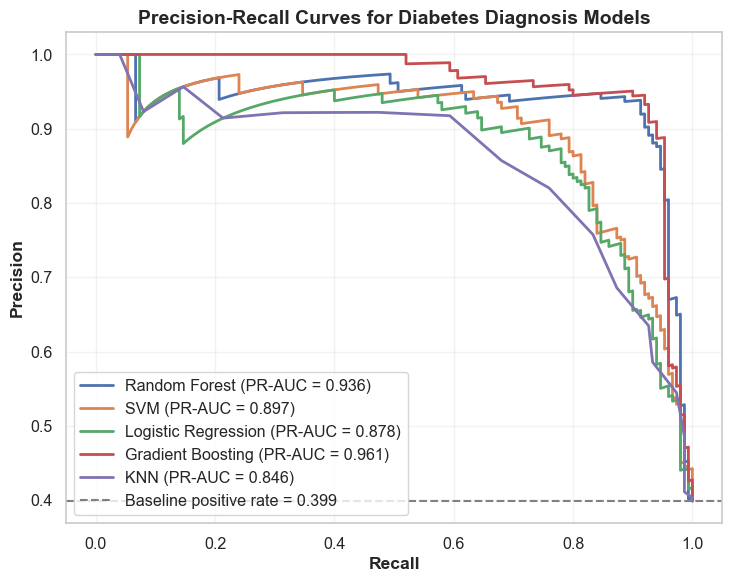

In [437]:
# Combined ROC curves
plt.figure(figsize=(7.5, 6))
for model_name in metrics_df["Model"]:
    y_prob = prediction_store[model_name]["y_prob"]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC = {auc_value:.3f})")
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    linewidth=1.5,
    label="Random classifier"
)
plt.xlabel("False Positive Rate", weight="bold")
plt.ylabel("True Positive Rate", weight="bold")
plt.title("ROC Curves for Diabetes Diagnosis Models", fontsize=14, weight="bold")
plt.legend(loc="lower right", frameon=True)
plt.grid(alpha=0.25)
plt.tight_layout()
# plt.savefig("../Data/figures/3_combined_roc_curves.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

# Combined PR curves
positive_rate = y_test.mean()
plt.figure(figsize=(7.5, 6))
for model_name in metrics_df["Model"]:
    y_prob = prediction_store[model_name]["y_prob"]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap_value = average_precision_score(y_test, y_prob)
    plt.plot(recall, precision, linewidth=2, label=f"{model_name} (PR-AUC = {ap_value:.3f})")
plt.axhline(
    y=positive_rate,
    linestyle="--",
    color="grey",
    linewidth=1.5,
    label=f"Baseline positive rate = {positive_rate:.3f}"
)
plt.xlabel("Recall", weight="bold")
plt.ylabel("Precision", weight="bold")
plt.title("Precision-Recall Curves for Diabetes Diagnosis Models", fontsize=14, weight="bold")
plt.legend(loc="lower left", frameon=True)
plt.grid(alpha=0.25)
plt.tight_layout()
# plt.savefig("../Data/figures/4_combined_pr_curves.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

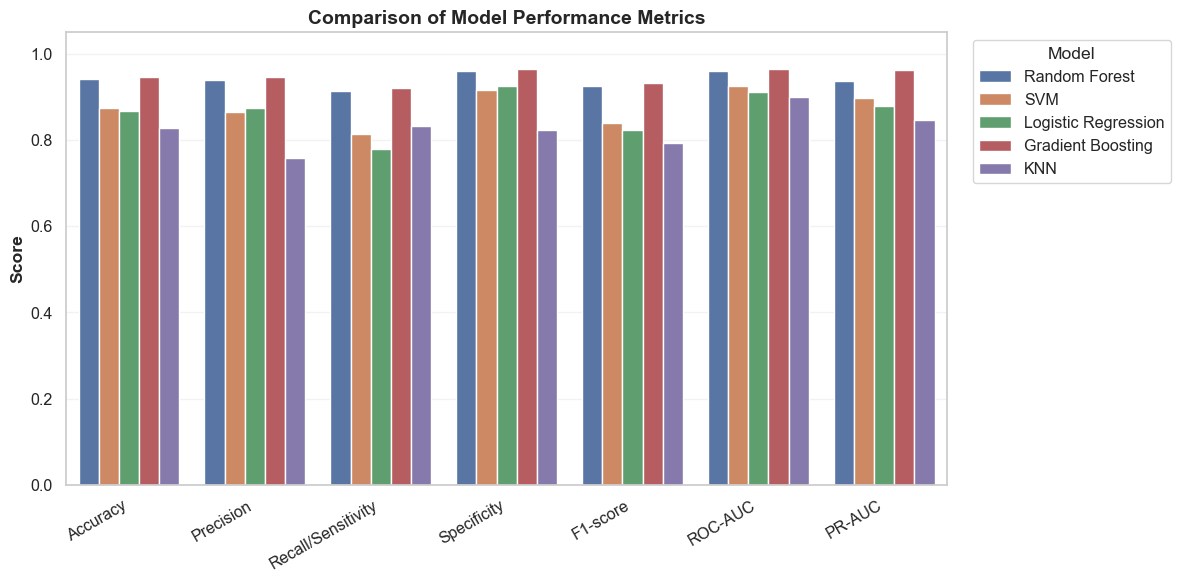

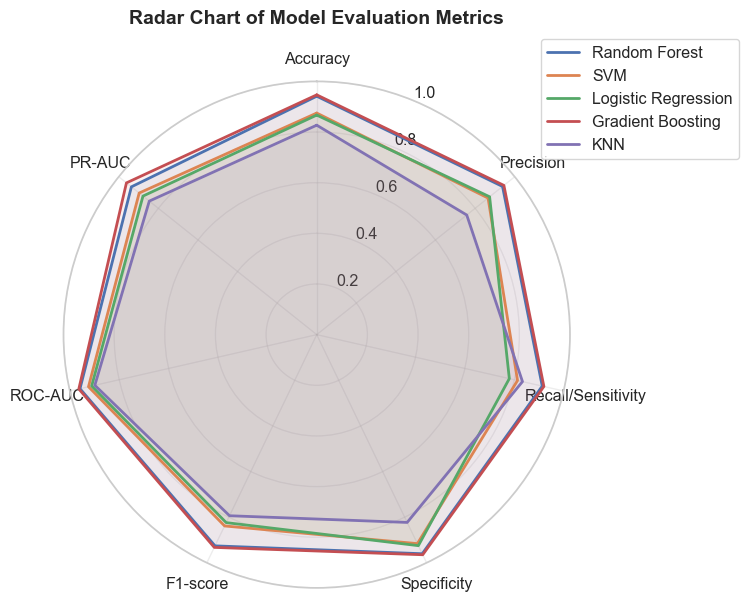

In [439]:
# Multi-metric comparison bar plot
plot_metrics = ["Accuracy", "Precision", "Recall/Sensitivity", "Specificity", "F1-score", "ROC-AUC", "PR-AUC"]
metrics_long = metrics_df.melt(
    id_vars="Model",
    value_vars=plot_metrics,
    var_name="Metric",
    value_name="Score"
)
plt.figure(figsize=(12, 6))
sns.barplot(
    data=metrics_long,
    x="Metric",
    y="Score",
    hue="Model"
)
plt.ylim(0, 1.05)
plt.ylabel("Score", weight="bold")
plt.xlabel("", weight="bold")
plt.title("Comparison of Model Performance Metrics", fontsize=14, weight="bold")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
# plt.savefig("../Data/figures/5_model_metric_comparison_barplot.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

# Multi-metric comparison radar chart
radar_metrics = plot_metrics
radar_df = metrics_df.set_index("Model")[radar_metrics]
labels = radar_metrics
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)
for model_name, row in radar_df.iterrows():
    values = row.tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=model_name)
    ax.fill(angles, values, alpha=0.08)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels)
ax.set_ylim(0, 1)
ax.set_title("Radar Chart of Model Evaluation Metrics", fontsize=14, weight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.10))
ax.grid(alpha=0.35)
plt.tight_layout()
# plt.savefig("../Data/figures/6_model_metric_radar_chart.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

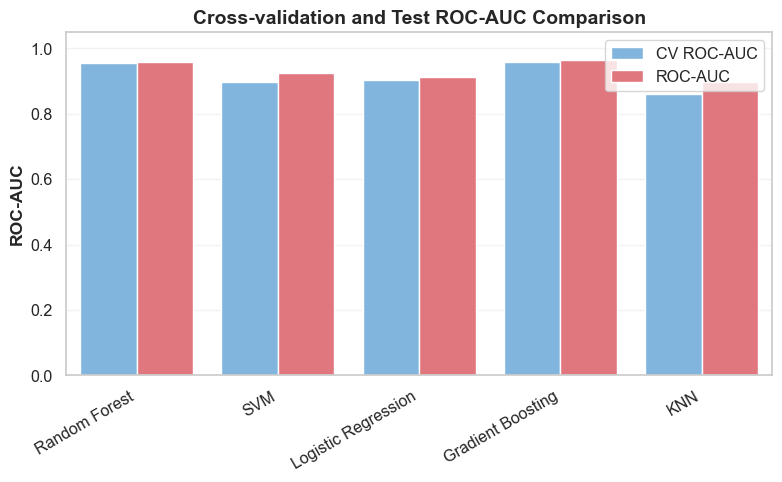

In [441]:
# CV ROC-AUC vs Best ROC-AUC
cv_auc_records = []
for model_name, item in models.items():
    cv_auc_records.append({
        "Model": model_name,
        "CV ROC-AUC": item["search"].best_score_
    })
cv_auc_df = pd.DataFrame(cv_auc_records)
metrics_df = metrics_df.merge(cv_auc_df, on="Model", how="left")
cv_test_df = metrics_df[["Model", "CV ROC-AUC", "ROC-AUC"]].copy()
# cv_test_df.round(4).to_csv("../Data/tables/4_cv_vs_test_roc_auc.csv")
cv_test_long = cv_test_df.melt(
    id_vars="Model",
    value_vars=["CV ROC-AUC", "ROC-AUC"],
    var_name="Evaluation Stage",
    value_name="ROC-AUC-value"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=cv_test_long,
    x="Model",
    y="ROC-AUC-value",
    hue="Evaluation Stage",
    palette=["#71b7ed", "#f2656f"]
)
plt.ylim(0, 1.05)
plt.ylabel("ROC-AUC", weight="bold")
plt.xlabel("", weight="bold")
plt.title("Cross-validation and Test ROC-AUC Comparison", fontsize=14, weight="bold")
plt.xticks(rotation=30, ha="right")
plt.legend(title="")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
# plt.savefig("../Data/figures/7_cv_vs_test_roc_auc.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

## 5. Feature importance analysis

### 1. Algorithm & function preparation
**Note that only top 10 features are showed for simplicity, increase value for parameter `top_n=10` for more features' information.**

In [327]:
def plot_top_importance(importance_df, x_col, y_col="Feature", title="Feature Importance", file_name=None, top_n=10):
    """
    Plot top——n feature importance as a horizontal bar plot.
    """
    plot_df = importance_df.sort_values(x_col, ascending=False).head(top_n).copy()
    plot_df = plot_df.sort_values(x_col, ascending=True)
    
    plt.figure(figsize=(8, 6))
    sns.barplot(
        data=plot_df,
        x=x_col,
        y=y_col,
        orient="h",
        palette='viridis',
        hue=y_col,
        legend=False
    )
    plt.xlabel(x_col, weight="bold")
    plt.ylabel("", weight="bold")
    plt.title(title, fontsize=14, weight="bold")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    if file_name is not None:
        plt.savefig(file_name, dpi=300, bbox_inches="tight", pad_inches=0.5)
    plt.show()

### 2. Coefficients (for Logistic Regression)

Logistic Regression coefficients:


,Feature,Coefficient,Abs_Coefficient
0,FastingBloodSugar,1.5032,1.5032
1,HbA1c,1.4084,1.4084
2,FrequentUrination,1.0396,1.0396
3,Hypertension,1.0231,1.0231
4,UnexplainedWeightLoss,0.5749,0.5749
5,ExcessiveThirst,0.4307,0.4307
6,SocioeconomicStatus_0,-0.1809,0.1809
7,SystolicBP,-0.0818,0.0818
8,CholesterolTriglycerides,0.0645,0.0645
9,QualityOfLifeScore,0.0302,0.0302


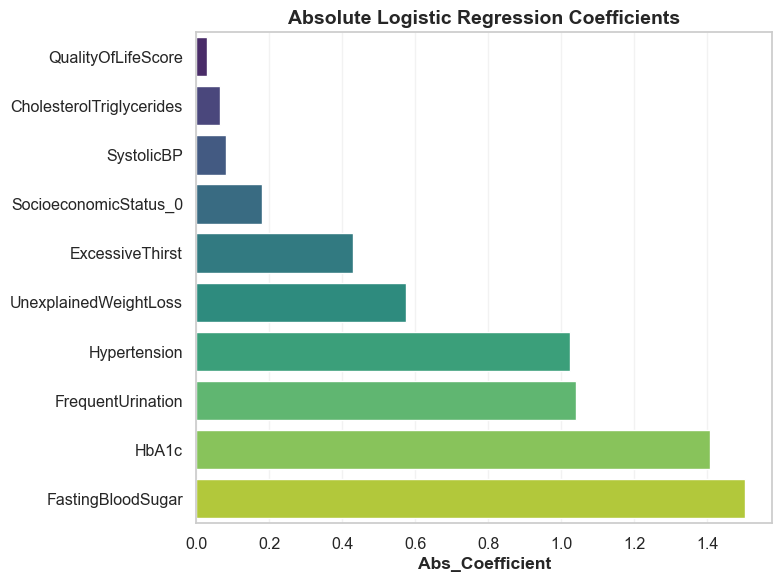

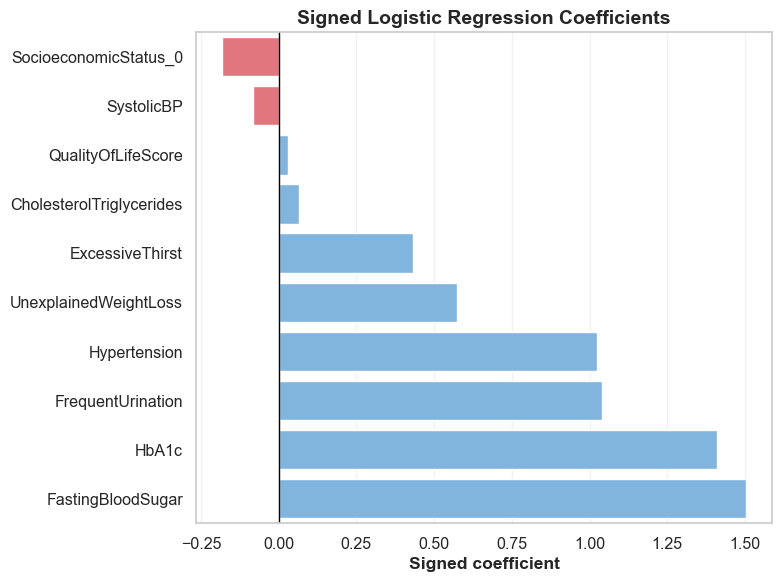

In [370]:
# Logistic Regression coefficients
# Data
lr_coef_df = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": best_lr.coef_[0]
})
lr_coef_df["Abs_Coefficient"] = lr_coef_df["Coefficient"].abs()
lr_coef_df = (
    lr_coef_df
    .sort_values("Abs_Coefficient", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
# lr_coef_df.to_csv("../Data/tables/5_logistic_regression_coefficients.csv", index=False)
print("Logistic Regression coefficients:")
display(lr_coef_df.head(10))

# Plot
plot_top_importance(
    importance_df=lr_coef_df,
    x_col="Abs_Coefficient",
    y_col="Feature",
    title="Absolute Logistic Regression Coefficients",
    # file_name="../Data/figures/8_logistic_regression_abs_coefficients.png",
    top_n=10
)

lr_signed_plot_df = (
    lr_coef_df
    .head(10)
    .sort_values("Coefficient", ascending=True)
)
signed_colors = [
    "#f2656f" if coef < 0 else "#71b7ed"
    for coef in lr_signed_plot_df["Coefficient"]
]
plt.figure(figsize=(8, 6))
sns.barplot(
    data=lr_signed_plot_df,
    x="Coefficient",
    y="Feature",
    orient="h",
    palette=signed_colors,
    hue="Feature",
    legend=False
)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Signed coefficient", weight="bold")
plt.ylabel("", weight="bold")
plt.title("Signed Logistic Regression Coefficients", fontsize=14, weight="bold")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
# plt.savefig("../Data/figures/9_logistic_regression_coefficients_signed.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

### 3. Feature Importance (for Random Forest & Gradient Boost)

Random Forest feature importance:


,Feature,RF_Importance
0,FastingBloodSugar,0.3040
1,HbA1c,0.2922
2,FrequentUrination,0.0237
3,HealthLiteracy,0.0187
4,SystolicBP,0.0184
5,BMI,0.0183
6,Hypertension,0.0182
7,DietQuality,0.0178
8,QualityOfLifeScore,0.0174
9,CholesterolTotal,0.0172


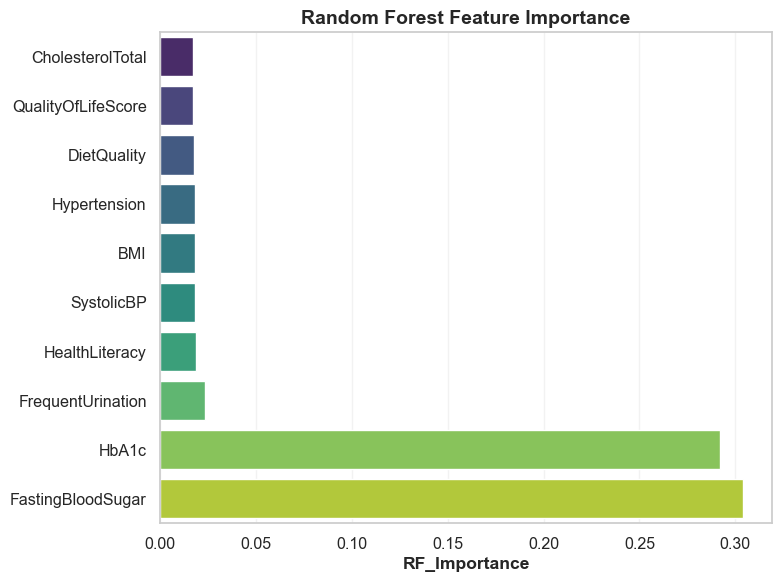

Gradient Boosting feature importance:


,Feature,GB_Importance
0,FastingBloodSugar,0.4169
1,HbA1c,0.3883
2,FrequentUrination,0.0414
3,Hypertension,0.0346
4,UnexplainedWeightLoss,0.0140
5,ExcessiveThirst,0.0120
6,FatigueLevels,0.0078
7,SleepQuality,0.0077
8,HealthLiteracy,0.0066
9,SystolicBP,0.0065


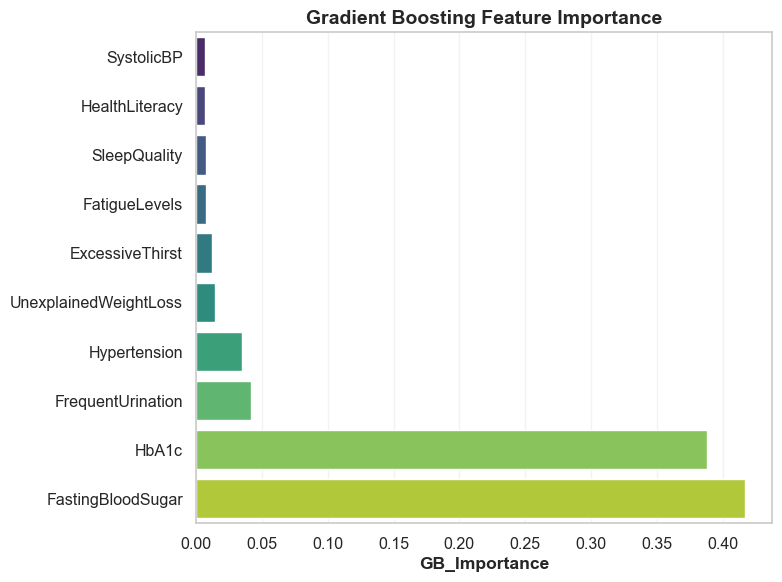

In [372]:
# Random Forest feature importance
# Data
rf_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "RF_Importance": best_rf.feature_importances_
})
rf_importance_df = (
    rf_importance_df
    .sort_values("RF_Importance", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
rf_importance_df.to_csv("../Data/tables/6_random_forest_builtin_importance.csv", index=False)
print("Random Forest feature importance:")
display(rf_importance_df.head(10))

# Plot
plot_top_importance(
    importance_df=rf_importance_df,
    x_col="RF_Importance",
    y_col="Feature",
    title="Random Forest Feature Importance",
    # file_name="../Data/figures/10_random_forest_feature_importance.png",
    top_n=10
)


# Gradient Boosting feature importance
# Data
gb_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "GB_Importance": best_gb.feature_importances_
})
gb_importance_df = (
    gb_importance_df
    .sort_values("GB_Importance", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
gb_importance_df.to_csv("../Data/tables/7_gradient_boosting_builtin_importance.csv", index=False)
print("Gradient Boosting feature importance:")
display(gb_importance_df.head(10))

# Plot
plot_top_importance(
    importance_df=gb_importance_df,
    x_col="GB_Importance",
    y_col="Feature",
    title="Gradient Boosting Feature Importance",
    # file_name="../Data/figures/11_gradient_boosting_feature_importance.png",
    top_n=10
)

### 4. SHAP Analysis (for Random Forest & Gradient Boosting)

SHAP calculation

In [354]:
# SHAP calculation
tree_shap_models = {
    "Random Forest": best_rf,
    "Gradient Boosting": best_gb
}
shap_tree_results = {}
X_shap = X_test.copy()
i = 8

for model_name, model in tree_shap_models.items():
    
    explainer = shap.TreeExplainer(model)
    shap_values_raw = explainer.shap_values(X_shap)
    
    if isinstance(shap_values_raw, list):
        shap_values_positive = shap_values_raw[1]
    else:
        shap_array = np.array(shap_values_raw)
        if shap_array.ndim == 3:
            shap_values_positive = shap_array[:, :, 1]
        else:
            shap_values_positive = shap_array
    
    shap_tree_results[model_name] = {
        "X_shap": X_shap,
        "shap_values": shap_values_positive,
        "explainer": explainer
    }
    
    shap_importance_df = pd.DataFrame({
        "Feature": X_shap.columns,
        "Mean_Abs_SHAP": np.abs(shap_values_positive).mean(axis=0)
    })
    
    shap_importance_df = (
        shap_importance_df
        .sort_values("Mean_Abs_SHAP", ascending=False)
        .reset_index(drop=True)
        .round(4)
    )

    safe_name = model_name.replace(" ", "_").lower()
    # shap_importance_df.to_csv(f"../Data/tables/{i}_shap_importance_{safe_name}.csv", index=False)
    i += 1
    
    print(f"{model_name} SHAP importance:")
    display(shap_importance_df.head(10))

Random Forest SHAP importance:


,Feature,Mean_Abs_SHAP
0,HbA1c,0.1685
1,FastingBloodSugar,0.1666
2,FrequentUrination,0.0301
3,Hypertension,0.0218
4,SystolicBP,0.0084
5,ExcessiveThirst,0.0067
6,DiastolicBP,0.0061
7,DietQuality,0.0059
8,QualityOfLifeScore,0.0056
9,BMI,0.0050


Gradient Boosting SHAP importance:


,Feature,Mean_Abs_SHAP
0,FastingBloodSugar,1.9073
1,HbA1c,1.8705
2,FrequentUrination,0.4878
3,Hypertension,0.3563
4,ExcessiveThirst,0.2847
5,UnexplainedWeightLoss,0.1869
6,DietQuality,0.0777
7,BMI,0.0776
8,CholesterolTotal,0.0773
9,Age,0.0559


SHAP summary plots for Random Forest & Gradient Boosting

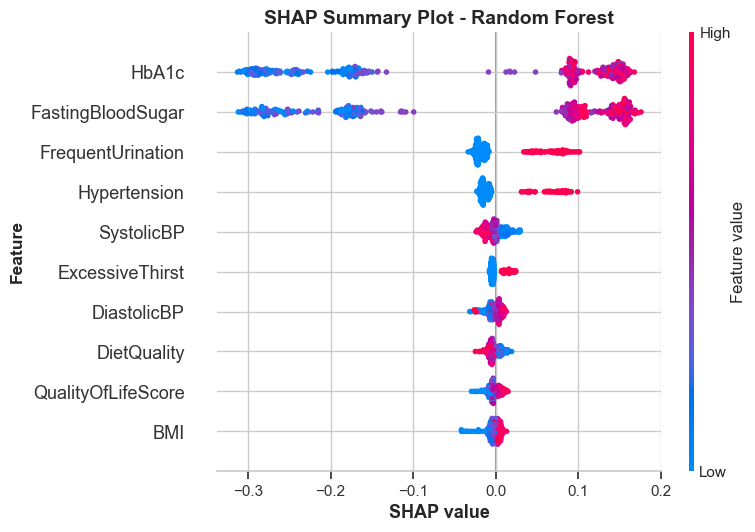

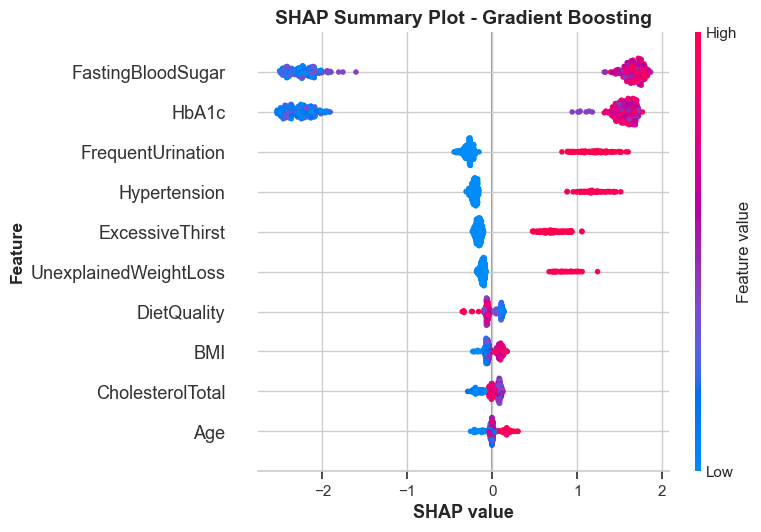

In [381]:
# SHAP summary plots
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    i = 12
    for model_name in ["Random Forest", "Gradient Boosting"]:
        safe_name = model_name.replace(" ", "_").lower()
        plt.figure(figsize=(8, 6))
        shap.summary_plot(
            shap_tree_results[model_name]["shap_values"],
            shap_tree_results[model_name]["X_shap"],
            max_display=10,
            show=False
        )
        plt.title(f"SHAP Summary Plot - {model_name}", fontsize=14, weight="bold")
        plt.xlabel("SHAP value", weight="bold")
        plt.ylabel("Feature", weight="bold")
        plt.tight_layout()
        # plt.savefig(f"../Data/figures/{i}_shap_summary_{safe_name}.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
        plt.show()
        i += 1

SHAP dependence plots for top 2 features of Gradient Boosting

<Figure size 700x550 with 0 Axes>

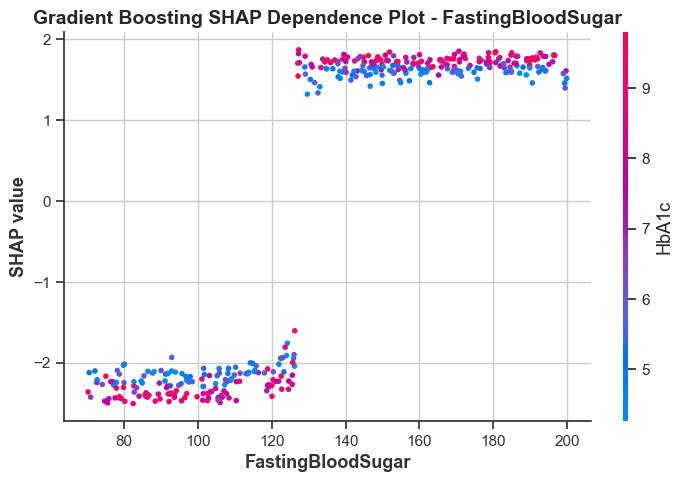

<Figure size 700x550 with 0 Axes>

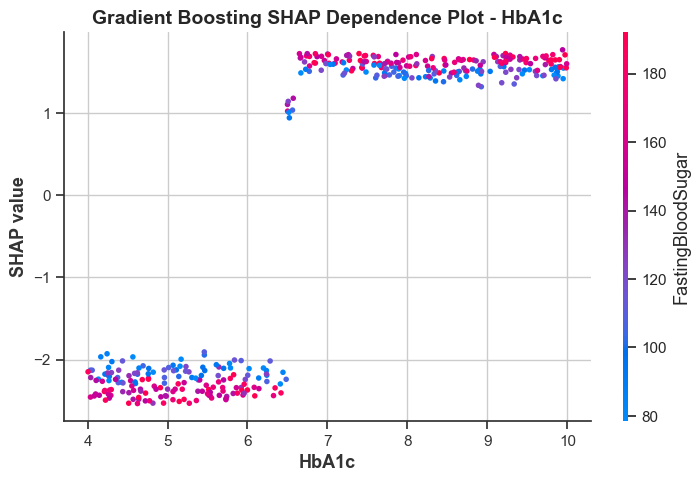

In [384]:
# SHAP dependence plots
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    i = 14
    gb_shap_values = shap_tree_results["Gradient Boosting"]["shap_values"]
    gb_X_shap = shap_tree_results["Gradient Boosting"]["X_shap"]
    gb_shap_importance_df = pd.DataFrame({
        "Feature": gb_X_shap.columns,
        "Mean_Abs_SHAP": np.abs(gb_shap_values).mean(axis=0)
    }).sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
    top2_features = gb_shap_importance_df.head(2)["Feature"].tolist()
    for feature in top2_features:
        plt.figure(figsize=(7, 5.5)) 
        shap.dependence_plot(
            feature,
            gb_shap_values,
            gb_X_shap,
            show=False
        )
        plt.title(f"Gradient Boosting SHAP Dependence Plot - {feature}", fontsize=14, weight="bold")
        plt.xlabel(feature, weight="bold")
        plt.ylabel("SHAP value", weight="bold")
        plt.tight_layout()
        plt.savefig(f"../Data/figures/{i}_gb_shap_dependence_{feature}.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
        plt.show()
        i += 1

### 5. Permutation Importance (for all five models)

Compute individual permutation importance for each model, then combine them

**This step is time-consuming, please wait for a while.**

In [404]:
# Data
# Permutation importance for individual models
permutation_results = {}
for model_name, item in models.items():
    model = item["model"]
    X_te = item["X_test"]
    perm = permutation_importance(
        estimator=model,
        X=X_te,
        y=y_test,
        scoring="roc_auc",
        n_repeats=10,
        random_state=42,
        n_jobs=1
    )
    perm_df = pd.DataFrame({
        "Feature": X_te.columns,
        "Permutation_Importance_Mean": perm.importances_mean,
        "Permutation_Importance_SD": perm.importances_std
    })
    perm_df = (
        perm_df
        .sort_values("Permutation_Importance_Mean", ascending=False)
        .reset_index(drop=True)
        .round(4)
    )
    permutation_results[model_name] = perm_df


# Combine permutation importance across all models
combined_perm_df = None
for model_name, perm_df in permutation_results.items():
    temp_df = perm_df[["Feature", "Permutation_Importance_Mean"]].copy()
    temp_df = temp_df.rename(columns={"Permutation_Importance_Mean": model_name})
    combined_perm_df = (
        temp_df if combined_perm_df is None
        else combined_perm_df.merge(temp_df, on="Feature", how="outer")
    )
combined_perm_df = combined_perm_df.fillna(0)
model_cols = [col for col in combined_perm_df.columns if col != "Feature"]
combined_perm_df["Mean_Permutation_Importance"] = combined_perm_df[model_cols].mean(axis=1)
combined_perm_df = (
    combined_perm_df
    .sort_values("Mean_Permutation_Importance", ascending=False)
    .reset_index(drop=True)
    .round(4)
)
# combined_perm_df.to_csv("../Data/tables/10_combined_permutation_importance_all_models.csv", index=False)
print("Combined permutation importance across all models:")
display(combined_perm_df.head(10))

Combined permutation importance across all models:


,Feature,Random Forest,SVM,Logistic Regression,Gradient Boosting,KNN,Mean_Permutation_Importance
0,HbA1c,0.2251,0.2052,0.2021,0.2211,0.1972,0.2101
1,FastingBloodSugar,0.2253,0.1951,0.1915,0.2207,0.1928,0.2051
2,FrequentUrination,0.0157,0.0224,0.0186,0.0178,0.0067,0.0162
3,Hypertension,0.0137,0.0144,0.0129,0.0124,0.0069,0.0121
4,ExcessiveThirst,0.0026,0.0106,0.0075,0.0070,0.0016,0.0059
5,CholesterolTotal,0.0012,-0.0007,0.0000,0.0014,0.0166,0.0037
6,CholesterolHDL,0.0027,0.0031,0.0000,0.0002,0.0096,0.0031
7,CholesterolLDL,0.0011,0.0044,0.0000,0.0001,0.0089,0.0029
8,HealthLiteracy,-0.0008,-0.0016,0.0000,0.0003,0.0164,0.0029
9,MedicalCheckupsFrequency,0.0014,0.0011,0.0000,-0.0004,0.0122,0.0029


Plots for combined permutation importance: bar plot & heatmap

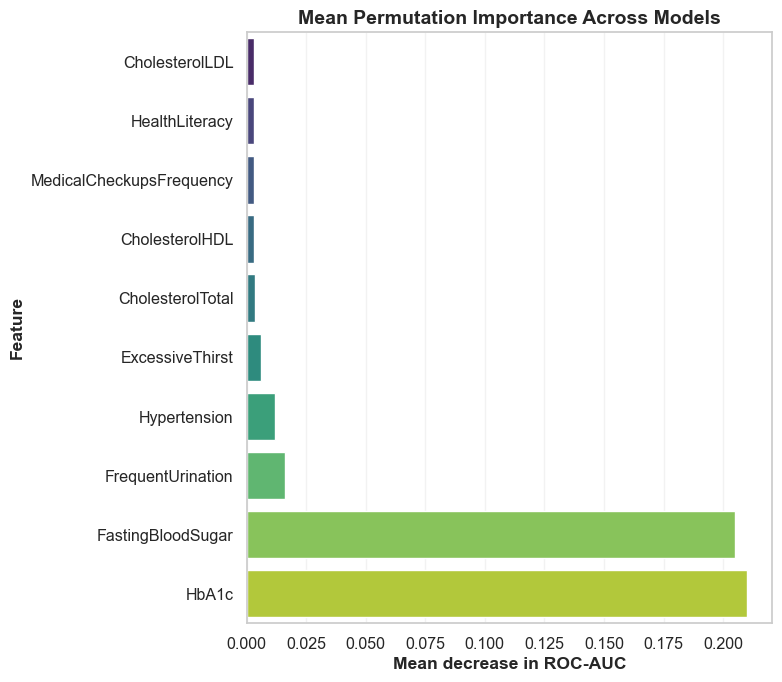

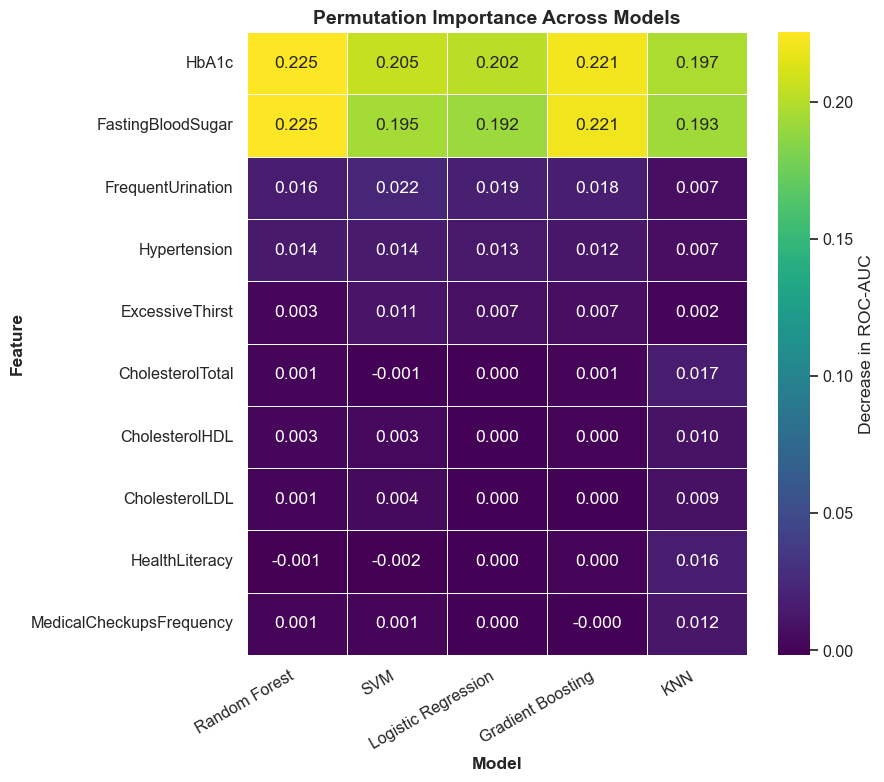

In [408]:
# Plot - bar chart
top_n = 10
mean_perm_plot_df = (
    combined_perm_df
    .head(top_n)
    .sort_values("Mean_Permutation_Importance", ascending=True)
)
plt.figure(figsize=(8, 7))
sns.barplot(
    data=mean_perm_plot_df,
    x="Mean_Permutation_Importance",
    y="Feature",
    orient="h",
    hue="Feature",
    palette="viridis",
    legend=False
)
plt.xlabel("Mean decrease in ROC-AUC", weight="bold")
plt.ylabel("Feature", weight="bold")
plt.title("Mean Permutation Importance Across Models", fontsize=14, weight="bold")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
# plt.savefig("../Data/figures/16_mean_permutation_importance_all_models.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

# Plot - heatmap
top_features = combined_perm_df.head(top_n)["Feature"].tolist()
heatmap_df = combined_perm_df.set_index("Feature").loc[top_features, model_cols]
plt.figure(figsize=(9, 8))
ax = sns.heatmap(
    heatmap_df,
    cmap="viridis",
    linewidths=0.4,
    linecolor="white",
    annot=True,
    fmt=".3f",
    cbar_kws={"label": "Decrease in ROC-AUC"}
)
ax.set_title("Permutation Importance Across Models", fontsize=14, weight="bold")
ax.set_xlabel("Model", weight="bold")
ax.set_ylabel("Feature", weight="bold")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
# plt.savefig("../Data/figures/17_permutation_importance_heatmap_all_models.png", dpi=300, bbox_inches="tight", pad_inches=0.5)
plt.show()

## 6. Conclusion (please see [`../reports/report.pdf`](../reports/report.pdf) for details)
- This project developed and compared five machine learning models for binary diabetes diagnosis using a multi-dimensional patient health dataset. All models exceeded the required 80% accuracy target. Gradient Boosting showed the highest performance and stability. It was therefore recommended as the best model. However, the other models also retained practical value, and multiple models could be used together as reference models or combined through a voting strategy to improve robustness.

- Model explanation results were consistent across cmethods. *FastingBloodSugar* and *HbA1c* were the dominant predictors. This pattern supports the clinical relevance of the trained models, since the strongest predictors align with glucose regulation and diabetes-related symptoms.

- The PEAS framework further translated the classifier into a hospital decision-support design, specifying performance goals, clinical environment, system outputs, and patient-data sources.